# Resultados Consolidados para o TCC — Figuras e Tabelas em LaTeX

Este notebook reúne **apenas as figuras e tabelas selecionadas para o texto do TCC e Apêndice**, consolidadas sobre as **30 sementes** nas **50 instâncias** (Datasets A = 20, B = 15, X = 15) para os 4 algoritmos (`OrderBased`, `AisleBased`, `ILS-VND` e `Santos e Baldotto (2025)`).

### Mapeamento dos Resultados Principais (R1–R5)
- **R1 (Construção orientada a corredores)**: Demonstrado pela **Tabela 1** (`tabela_sintese_geral.tex`), **Tabela 2** (`tabela_estrutura.tex`) e **Figura 1** (`perf_profile.pdf`).
- **R2 (Eficácia do refinamento pelo ILS-VND)**: Demonstrado pela **Tabela 3** (`tabela_dominancia.tex`), **Figura 4** (`refinamento_ils_vnd.pdf`) e **Figura 5** (`refinamento_faixas.pdf`).
- **R3 (ILS-VND vs. Referência)**: distribuição do RPD em `boxplot_rpd.pdf` e `boxplot_metaheuristicas.pdf`. Os testes estatísticos ficam **exclusivamente** em `testes_estatisticos.ipynb`.
- **R4 (Descoberta de novas Melhores Soluções Conhecidas em B/0012 e B/0013)**: Demonstrado pelas figuras `novas_msc_comparativo_b0012.pdf`, `novas_msc_comparativo_b0013.pdf` e `novas_msc_sementes.pdf` e pelas **Tabelas do Apêndice** (`tabela_apendice_b.tex`, `tabela_obj_b.tex`, `tabela_rpd_dp_b.tex`).
- **R5 (Compromisso Tempo × Qualidade e Estabilidade entre Sementes)**: Demonstrado pela **Figura 1** (`perf_profile.pdf`), `tradeoff_tempo_qualidade.pdf` e `estabilidade_sementes.pdf`.

### Revisões Implementadas
1. **Unidade correta do Desvio Padrão**: Nas tabelas de RPD, o valor após $\pm$ agora é o **desvio padrão amostral do RPD (em p.p.)**, e não o desvio padrão da função objetivo bruta.
2. **Correção de sintaxe e padrão LaTeX (ABNT/booktabs)**: Escape correto do símbolo `\%` em `tabela_dominancia.tex`, uso de `\toprule`, `\midrule`, `\bottomrule`, alinhamento numérico à direita (`r`) e separador decimal com **vírgula** em todas as tabelas e gráficos.
3. **Tolerância unificada (`TOL = 1e-4`, ou 0,01%)**: Aplicada de forma consistente em #MSC, placares V/E/D e Perfis de Desempenho $\rho_s(\tau)$.
4. **Correção de escala e zoom competitivo nos gráficos**:
   - Nos Perfis de Desempenho de qualidade (`perf_profile.pdf`), janela competitiva $\tau \in [1{,}00; 1{,}12]$ para evitar que o `OrderBased` comprima `AisleBased`, `ILS-VND` e `Santos e Baldotto (2025)` sobre o eixo vertical.
   - Nos Boxplots (`boxplot_rpd.pdf` e `boxplot_metaheuristicas.pdf`), figuras individuais sem compressão de escala.
   - Na estabilidade entre sementes (`estabilidade_sementes.pdf`), representação direta das 12 instâncias com variabilidade não nula (substituindo o boxplot com quartis zerados).
   - Figuras desmembradas em gráficos individuais e focados, com proporções harmônicas e legendas desimpedidas para inclusão direta no texto via `\caption{}` e `\includegraphics{}` no LaTeX.


In [1]:
from pathlib import Path
import math
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "utils" / "__init__.py").exists())
RESULTS = ROOT / "project" / "results"
BEST_CSV = ROOT / "best_solutions" / "best_objectives.csv"
IMG = ROOT / "notebooks" / "resultados" / "img"; IMG.mkdir(parents=True, exist_ok=True)
TEX = ROOT / "notebooks" / "resultados" / "tex"; TEX.mkdir(parents=True, exist_ok=True)

DATASETS = ["a", "b", "x"]
ALGOS = {
    "order_based": "OrderBased",
    "aisle_based": "AisleBased",
    "ils_vnd_all": "ILS-VND",
    "andre_feijo_all": "Santos e Baldotto (2025)",
}
NOMES = list(ALGOS.values())
COMPETITIVOS = ["AisleBased", "ILS-VND", "Santos e Baldotto (2025)"]
META = ["ILS-VND", "Santos e Baldotto (2025)"]
PRINCIPAL = "ILS-VND"
CONTROLE = "Santos e Baldotto (2025)"

COR = {
    "OrderBased": "#7f7f7f",
    "AisleBased": "#1f77b4",
    "ILS-VND": "#d62728",
    "Santos e Baldotto (2025)": "#2ca02c",
}
MARCADOR = {
    "OrderBased": "s",
    "AisleBased": "^",
    "ILS-VND": "o",
    "Santos e Baldotto (2025)": "D",
}

TOL = 1e-4       # tolerância relativa (0,01%) unificada
ALPHA = 0.05
RNG_SEED = 12345

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
})

def vrg(s):
    '''Formata ponto decimal para vírgula (padrão PT-BR).'''
    return str(s).replace(".", ",")

def fmt_num(v, casas=2, sinal=False):
    if pd.isna(v):
        return "—"
    fmt = f"{{:+.{casas}f}}" if sinal else f"{{:.{casas}f}}"
    return vrg(fmt.format(float(v)))

def fmt_pm(m, dp, casas=2, ocultar_dp_zero=True):
    ms = fmt_num(m, casas)
    if pd.isna(dp) or (ocultar_dp_zero and abs(dp) < 0.5 * 10**(-casas)):
        return ms
    return f"{ms} $\\pm$ {fmt_num(dp, casas)}"

def fmt_p_tex(v):
    if pd.isna(v):
        return "—"
    if v < 1e-3:
        return r"$<0{,}001$"
    return vrg(f"{v:.3f}")

def salvar_tex(nome, linhas):
    texto = "\n".join(linhas) if isinstance(linhas, list) else str(linhas)
    caminho = TEX / f"{nome}.tex"
    caminho.write_text(texto.strip() + "\n", encoding="utf-8")
    print(f"[LaTeX salvo] {caminho.relative_to(ROOT)}")

def salvar_fig(fig, nome, caption, label, width=r"\textwidth"):
    for ext in ("pdf", "png"):
        fig.savefig(IMG / f"{nome}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    bloco = [
        r"\begin{figure}[htbp]",
        r"  \centering",
        rf"  \caption{{{caption}}}",
        rf"  \label{{{label}}}",
        rf"  \includegraphics[width={width}]{{img/{nome}.pdf}}",
        r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
        r"\end{figure}",
    ]
    salvar_tex(f"fig_{nome}", bloco)
    print(f"[Figura salva] img/{nome}.pdf | img/{nome}.png")

# --- Carga e validação dos dados (6.000 execuções) ---
frames = []
for folder, label in ALGOS.items():
    for ds in DATASETS:
        for f in sorted((RESULTS / folder / ds).glob("instance_*.csv")):
            d = pd.read_csv(f, usecols=["run_id", "seed", "status", "objective", "items", "aisles", "exec_time"])
            d["algo"], d["dataset"], d["instance"] = label, ds, f.stem + ".txt"
            frames.append(d)
raw = pd.concat(frames, ignore_index=True)
best = pd.read_csv(BEST_CSV).rename(columns={"best_objective": "best"})
raw = raw.merge(best, on=["dataset", "instance"], how="left")

assert (raw["status"] == "feasible").all(), "Há execuções inviáveis!"
assert raw["objective"].notna().all() and raw["best"].notna().all()

# RPD de cada seed (%)
raw["rpd"] = (raw["best"] - raw["objective"]) / raw["best"] * 100.0

agg = (
    raw.groupby(["dataset", "instance", "algo"], as_index=False)
    .agg(
        obj_mean=("objective", "mean"),
        obj_dp=("objective", lambda s: s.std(ddof=1)),
        obj_max=("objective", "max"),
        rpd_mean=("rpd", "mean"),
        rpd_dp=("rpd", lambda s: s.std(ddof=1)),
        rpd_min=("rpd", "min"),
        items_mean=("items", "mean"),
        aisles_mean=("aisles", "mean"),
        tempo_mean=("exec_time", "mean"),
        tempo_dp=("exec_time", lambda s: s.std(ddof=1)),
        best=("best", "first"),
        n=("objective", "size"),
    )
)
assert (agg["n"] == 30).all(), "Todas as instâncias devem ter exatamente 30 seeds!"

def pv(col):
    return agg.pivot(index=["dataset", "instance"], columns="algo", values=col)[NOMES]

OBJ = pv("obj_mean")
OBJ_DP = pv("obj_dp")
RPD = pv("rpd_mean")
RPD_DP = pv("rpd_dp")
ITEMS = pv("items_mean")
AISLES = pv("aisles_mean")
TEMPO = pv("tempo_mean")
BEST = best.set_index(["dataset", "instance"])["best"].reindex(OBJ.index)

N, K = OBJ.shape
ds_idx = OBJ.index.get_level_values("dataset")
print(f"Dados validados: {len(raw)} execuções | N = {N} instâncias | k = {K} algoritmos | 30 seeds/instância.")


Dados validados: 6000 execuções | N = 50 instâncias | k = 4 algoritmos | 30 seeds/instância.


## 1. Quadro Sinótico Geral e Decomposição Estrutural (Tabelas 1 e 2)

- **`tabela_sintese_geral.tex`**: Consolida por dataset e no Geral as métricas de qualidade (**RPD médio $\pm$ DP entre instâncias**, **RPD mediano**, **$\text{RPD} \le 1\%$**, **#MSC**) e esforço computacional (**Tempo médio $\pm$ DP**).
- **`tabela_estrutura.tex`**: Explica o mecanismo físico da razão $\text{Unidades}/\text{Corredores}$ (Resultados **R1** e **R2**), mostrando como o `OrderBased` explode o denominador e como o `ILS-VND` refina a solução do `AisleBased`.


In [2]:
# --- Tabela 1: Quadro Sinótico Geral e por Dataset ---
linhas_sintese = []
grupos_ds = [("A", ds_idx == "a"), ("B", ds_idx == "b"), ("X", ds_idx == "x"), ("Geral", np.ones(N, dtype=bool))]

tex_sint = [
    r"\begin{table}[htbp]",
    r"  \centering",
    r"  \caption{\label{tab:sintese_geral} Desempenho comparativo dos algoritmos por conjunto de instâncias (médias de 30 sementes por instância).}",
    r"  \resizebox{\textwidth}{!}{",
    r"    \begin{tabular}{l l r r c c r}",
    r"      \toprule",
    r"      \textbf{Dataset ($N$)} & \textbf{Algoritmo} & \textbf{RPD Médio $\pm$ DP (\%)} & \textbf{RPD Med. (\%)} & \textbf{RPD $\le 1\%$} & \textbf{\#MSC} & \textbf{Tempo Médio $\pm$ DP (s)} \\",
    r"      \midrule",
]

for g_nome, mask in grupos_ds:
    n_inst = int(np.sum(mask))
    rotulo_ds = f"{g_nome} ({n_inst})"
    for j, a in enumerate(NOMES):
        rpd_s = RPD.loc[mask, a]
        obj_s = OBJ.loc[mask, a]
        b_s = BEST.loc[mask]
        t_s = TEMPO.loc[mask, a]

        rpd_m, rpd_sd, rpd_med = rpd_s.mean(), rpd_s.std(ddof=1), rpd_s.median()
        n_le1 = int((rpd_s <= 1.0 + 1e-9).sum())
        n_msc = int((obj_s >= b_s * (1.0 - TOL)).sum())
        t_m, t_sd = t_s.mean(), t_s.std(ddof=1)

        linhas_sintese.append({
            "Dataset": rotulo_ds,
            "Algoritmo": a,
            "RPD Médio ± DP (%)": f"{fmt_num(rpd_m)} ± {fmt_num(rpd_sd)}",
            "RPD Med. (%)": fmt_num(rpd_med),
            "RPD <= 1%": f"{n_le1}/{n_inst}",
            "#MSC": f"{n_msc}/{n_inst}",
            "Tempo Médio ± DP (s)": f"{fmt_num(t_m)} ± {fmt_num(t_sd)}",
        })

        ds_cell = rf"\multirow{{4}}{{*}}{{\textbf{{{rotulo_ds}}}}}" if j == 0 else ""
        a_tex = rf"\textbf{{{a}}}" if a == PRINCIPAL else a
        tex_sint.append(
            f"      {ds_cell} & {a_tex} & {fmt_pm(rpd_m, rpd_sd, ocultar_dp_zero=False)} & "
            f"{fmt_num(rpd_med)} & {n_le1}/{n_inst} & {n_msc}/{n_inst} & "
            rf"{fmt_pm(t_m, t_sd, ocultar_dp_zero=False)} \\"
        )
    tex_sint.append(r"      \midrule" if g_nome != "Geral" else r"      \bottomrule")

tex_sint += [
    r"    \end{tabular}",
    r"  }",
    r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
    r"\end{table}",
]
salvar_tex("tabela_sintese_geral", tex_sint)
display(pd.DataFrame(linhas_sintese))

# --- Tabela 2: Decomposição Estrutural (Unidades Coletadas e Corredores Visitados) ---
linhas_est = []
tex_est = [
    r"\begin{table}[htbp]",
    r"  \centering",
    r"  \caption{\label{tab:estrutura} Decomposição estrutural das soluções: unidades coletadas (numerador) e corredores visitados (denominador), médias de 30 sementes.}",
    r"  \begin{tabular}{l l r r r r}",
    r"    \toprule",
    r"    \textbf{Dataset ($N$)} & \textbf{Algoritmo} & \textbf{Unidades (Med.)} & \textbf{Unidades (Méd.)} & \textbf{Corredores (Med.)} & \textbf{Corredores (Méd.)} \\",
    r"    \midrule",
]

for g_nome, mask in grupos_ds:
    n_inst = int(np.sum(mask))
    rotulo_ds = f"{g_nome} ({n_inst})"
    for j, a in enumerate(NOMES):
        u_s = ITEMS.loc[mask, a]
        c_s = AISLES.loc[mask, a]
        u_med, u_m = u_s.median(), u_s.mean()
        c_med, c_m = c_s.median(), c_s.mean()
        linhas_est.append({
            "Dataset": rotulo_ds, "Algoritmo": a,
            "Unidades (Med.)": fmt_num(u_med, 1), "Unidades (Méd.)": fmt_num(u_m, 1),
            "Corredores (Med.)": fmt_num(c_med, 1), "Corredores (Méd.)": fmt_num(c_m, 1),
        })
        ds_cell = rf"\multirow{{4}}{{*}}{{\textbf{{{rotulo_ds}}}}}" if j == 0 else ""
        a_tex = rf"\textbf{{{a}}}" if a == PRINCIPAL else a
        tex_est.append(
            f"    {ds_cell} & {a_tex} & {fmt_num(u_med, 1)} & {fmt_num(u_m, 1)} & "
            rf"{fmt_num(c_med, 1)} & {fmt_num(c_m, 1)} \\"
        )
    tex_est.append(r"    \midrule" if g_nome != "Geral" else r"    \bottomrule")

tex_est += [
    r"  \end{tabular}",
    r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
    r"\end{table}",
]
salvar_tex("tabela_estrutura", tex_est)
display(pd.DataFrame(linhas_est))


[LaTeX salvo] notebooks/resultados/tex/tabela_sintese_geral.tex


,Dataset,Algoritmo,RPD Médio ± DP (%),RPD Med. (%),RPD <= 1%,#MSC,Tempo Médio ± DP (s)
0,A (20),OrderBased,"69,30 ± 27,29","80,22",1/20,1/20,"13,45 ± 15,02"
1,A (20),AisleBased,"6,15 ± 10,39","0,11",12/20,10/20,"0,43 ± 0,45"
2,A (20),GVNS,"0,15 ± 0,49","0,00",19/20,17/20,"317,19 ± 270,45"
3,A (20),Santos e Baldotto (2025),"0,02 ± 0,06","0,00",20/20,18/20,"70,49 ± 151,10"
4,B (15),OrderBased,"88,75 ± 8,28","92,36",0/15,0/15,"19,45 ± 13,20"
5,B (15),AisleBased,"2,16 ± 2,45","0,85",8/15,4/15,"2,41 ± 3,05"
6,B (15),GVNS,"0,03 ± 0,06","0,00",15/15,10/15,"568,40 ± 90,13"
7,B (15),Santos e Baldotto (2025),"0,02 ± 0,06","0,00",15/15,12/15,"222,19 ± 236,98"
8,X (15),OrderBased,"90,40 ± 7,57","94,43",0/15,0/15,"15,68 ± 13,68"
9,X (15),AisleBased,"1,98 ± 2,32","0,70",8/15,2/15,"3,76 ± 3,87"


[LaTeX salvo] notebooks/resultados/tex/tabela_estrutura.tex


,Dataset,Algoritmo,Unidades (Med.),Unidades (Méd.),Corredores (Med.),Corredores (Méd.)
0,A (20),OrderBased,"1102,0","1919,4","81,5","127,2"
1,A (20),AisleBased,"324,5","767,6","4,0","20,1"
2,A (20),GVNS,"269,5","614,7","4,0","7,1"
3,A (20),Santos e Baldotto (2025),"269,5","686,0","4,0","10,8"
4,B (15),OrderBased,"3968,0","7814,0","327,0","270,9"
5,B (15),AisleBased,"2260,0","3041,5","10,0","10,4"
6,B (15),GVNS,"2271,0","3021,2","10,0","10,1"
7,B (15),Santos e Baldotto (2025),"2271,0","3032,2","10,0","10,3"
8,X (15),OrderBased,"5518,0","11886,1","368,0","294,3"
9,X (15),AisleBased,"2367,0","3377,9","7,0","8,4"


## 2. Dominância Direta do ILS-VND (Tabela 3)

- **`tabela_dominancia.tex`**: Placar de Vitórias (V), Empates (E) e Derrotas (D) do `ILS-VND` contra os demais métodos, com tolerância relativa `TOL = 0,01%` e sintaxe `\%` corrigida.
- Os testes de Friedman e Wilcoxon-Holm foram movidos para `testes_estatisticos.ipynb`.

In [3]:
# --- Tabela 3: Dominância Direta do ILS-VND ---
OPONENTES = [a for a in NOMES if a != PRINCIPAL]

def cmp_tol(a, b):
    ref = np.maximum(np.abs(a), np.abs(b))
    return np.where(np.abs(a - b) <= TOL * ref, 0, np.sign(a - b)).astype(int)

res_dom = pd.DataFrame(index=OBJ.index)
res_dom["msc"] = OBJ[PRINCIPAL] >= BEST * (1.0 - TOL)
for o in OPONENTES:
    res_dom[o] = cmp_tol(OBJ[PRINCIPAL].values, OBJ[o].values)

linhas_dom = {}
for ds in DATASETS + ["Total"]:
    r = res_dom if ds == "Total" else res_dom.loc[ds]
    lin = {("", "N"): len(r), ("", "#MSC"): int(r["msc"].sum())}
    for o in OPONENTES:
        lin[(f"vs. {o}", "V")] = int((r[o] > 0).sum())
        lin[(f"vs. {o}", "E")] = int((r[o] == 0).sum())
        lin[(f"vs. {o}", "D")] = int((r[o] < 0).sum())
    linhas_dom["Total" if ds == "Total" else ds.upper()] = lin

tab_dom = pd.DataFrame(linhas_dom).T
tab_dom.columns = pd.MultiIndex.from_tuples(tab_dom.columns)
tab_dom.index.name = "Dataset"
display(tab_dom)

nop = len(OPONENTES)
tex_dom = [
    r"\begin{table}[htbp]",
    r"  \centering",
    rf"  \caption{{\label{{tab:dominancia}} Dominância direta do {PRINCIPAL} (V = vitórias, E = empates, D = derrotas) e \#MSC sobre a média de 30 sementes (tolerância relativa de {vrg(f'{TOL*100:.2f}')}\%).}}",
    r"  \begin{tabular}{l r r " + " ".join(["r r r"] * nop) + "}",
    r"    \toprule",
    r"    \multirow{2}{*}{\textbf{Dataset}} & \multirow{2}{*}{\textbf{$N$}} & \multirow{2}{*}{\textbf{\#MSC}} & "
    + " & ".join(rf"\multicolumn{{3}}{{c}}{{\textbf{{vs. {o}}}}}" for o in OPONENTES) + r" \\",
    "    " + " ".join(rf"\cmidrule(lr){{{4 + 3*k}-{6 + 3*k}}}" for k in range(nop)),
    r"    & & & " + " & ".join(r"\textbf{V} & \textbf{E} & \textbf{D}" for _ in OPONENTES) + r" \\",
    r"    \midrule",
]
for idx, row in tab_dom.iterrows():
    if idx == "Total":
        tex_dom.append(r"    \midrule")
    vals = " & ".join(str(int(v)) for v in row)
    nome_l = rf"\textbf{{{idx}}}" if idx == "Total" else idx
    tex_dom.append(rf"    {nome_l} & {vals} \\")
tex_dom += [
    r"    \bottomrule",
    r"  \end{tabular}",
    r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
    r"\end{table}",
]
salvar_tex("tabela_dominancia", tex_dom)


vs. OrderBased       vs. AisleBased         \
          N #MSC              V  E  D              V   E  D   
Dataset                                                       
A        20   17             19  1  0             10  10  0   
B        15   10             15  0  0             12   3  0   
X        15    9             15  0  0             11   4  0   
Total    50   36             49  1  0             33  17  0   

        vs. Santos e Baldotto (2025)          
                                   V   E   D  
Dataset                                       
A                                  0  17   3  
B                                  3   8   4  
X                                  2   7   6  
Total                              5  32  13

[LaTeX salvo] notebooks/resultados/tex/tabela_dominancia.tex


## 3. Figura 1: Perfis de Desempenho de Dolan & Moré (`perf_profile.pdf`)

**Revisões aplicadas**:
- Na linha superior (Qualidade — RPD), o eixo horizontal foi ajustado para a **janela competitiva $\tau \in [1{,}00; 1{,}12]$** (custo relativo até $+12\%$), permitindo distinguir perfeitamente a subida de `Santos e Baldotto (2025)`, `ILS-VND` e `AisleBased` que antes ficavam esmagadas no eixo esquerdo.
- A condição de vitória em $\tau = 1$ utiliza a mesma tolerância `TOL = 1e-4` das tabelas.


[LaTeX salvo] notebooks/resultados/tex/fig_perf_profile.tex
[Figura salva] img/perf_profile.pdf | img/perf_profile.png


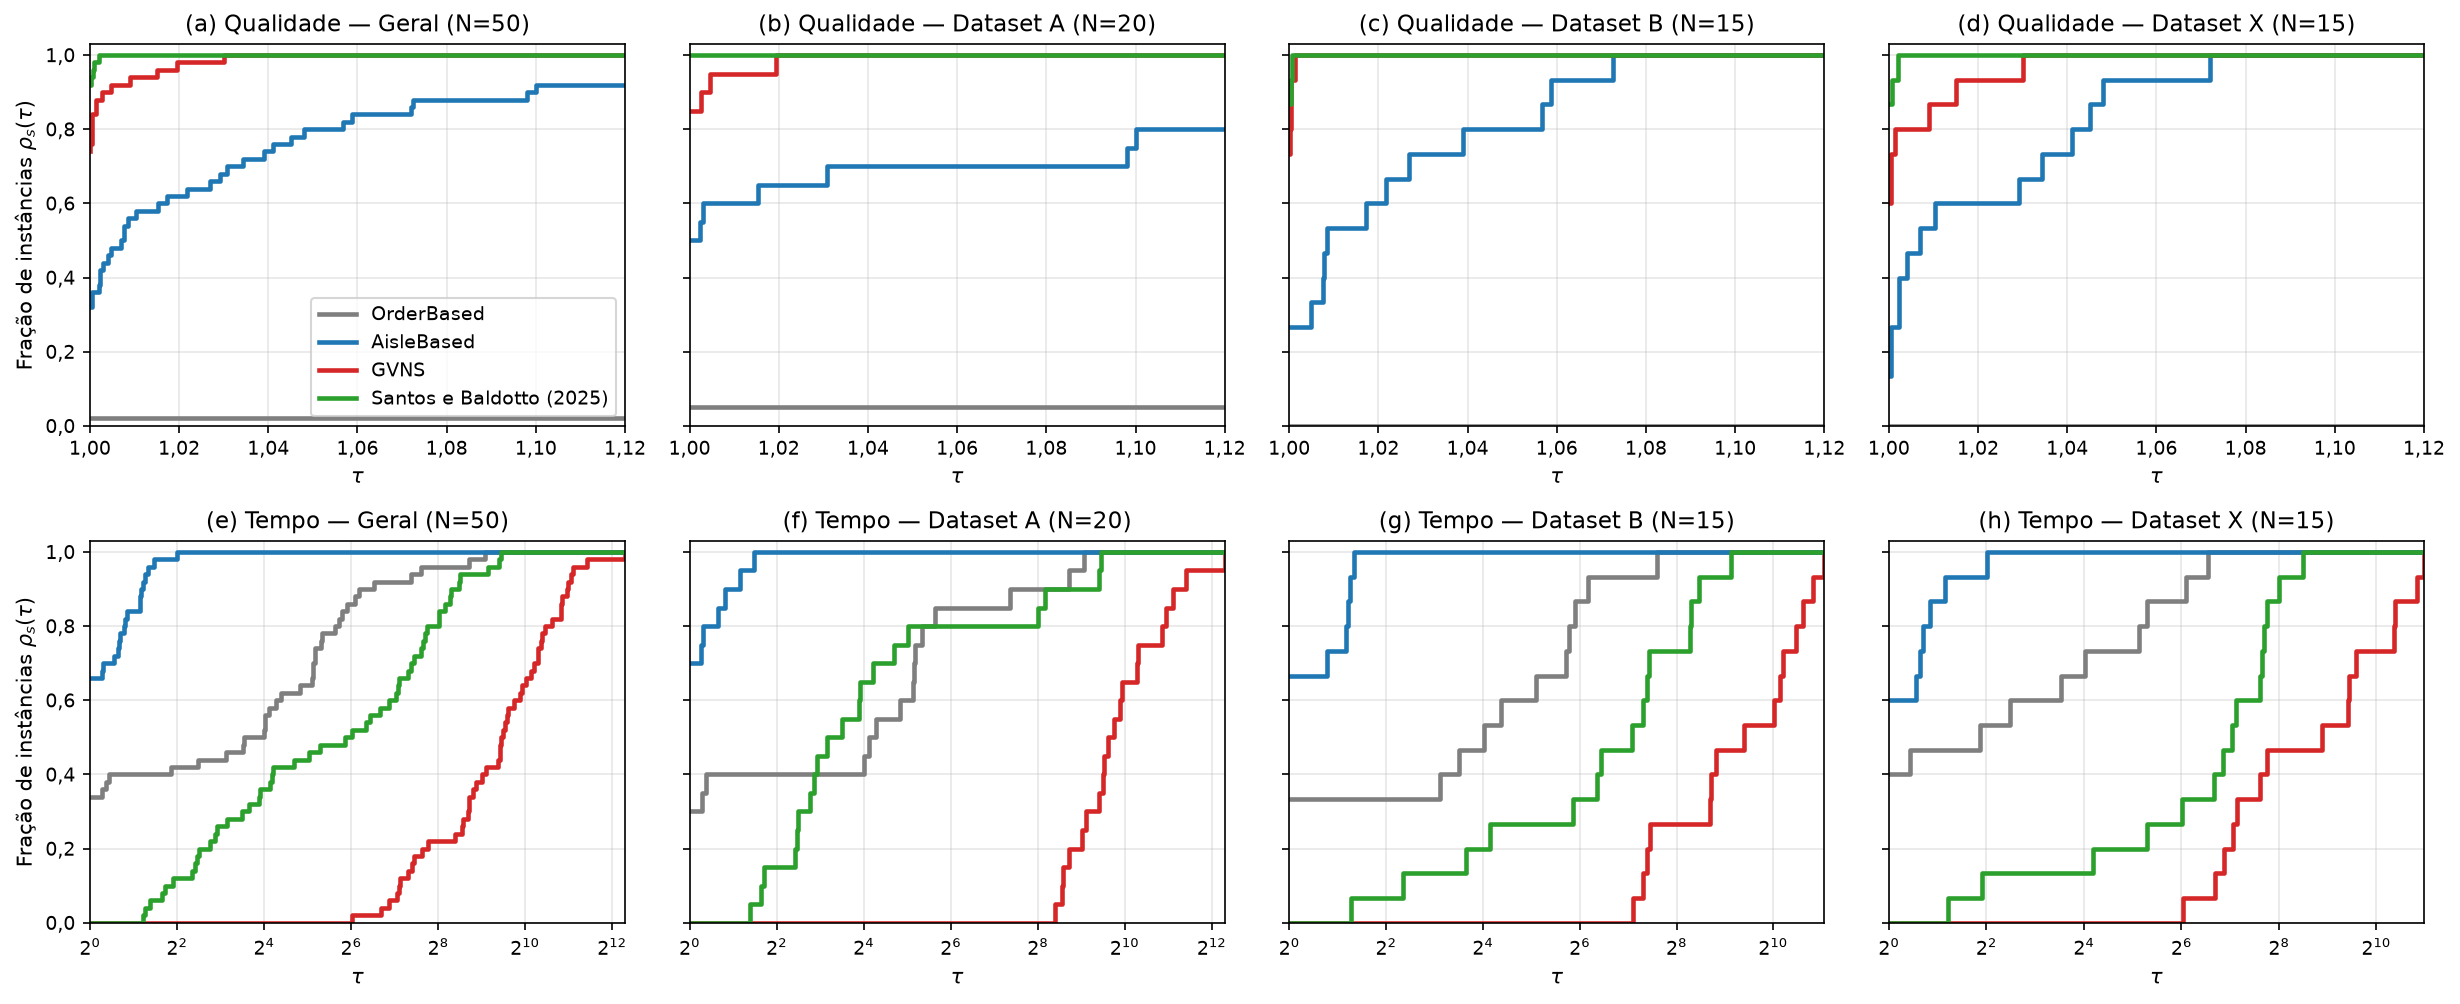

In [4]:
def razoes_custo(C):
    return C.div(C.min(axis=1), axis=0)

def plot_perfil(ax, C, titulo, xmax=None, log=False, tol_empate=TOL):
    r = razoes_custo(C)
    tmax = float(r.values.max()) if xmax is None else float(xmax)
    valores_r = r.values.ravel()
    valores_r = valores_r[valores_r <= tmax]
    taus = np.unique(np.concatenate([[1.0], valores_r, np.linspace(1.0, tmax, 250), [tmax]]))
    for a in NOMES:
        rho = [(r[a].values <= t * (1.0 + tol_empate)).mean() for t in taus]
        ax.step(taus, rho, where="post", label=a, color=COR[a], lw=2.2)
    if log:
        ax.set_xscale("log", base=2)
    else:
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: vrg(f"{x:.2f}")))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: vrg(f"{y:.1f}")))
    ax.set_ylim(0, 1.03)
    ax.set_xlim(1.0, tmax)
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.set_xlabel(r"$\tau$")

CUSTO_Q = 1.0 + RPD.clip(lower=0.0) / 100.0
CUSTO_T = TEMPO.clip(lower=1e-3)
paineis_ds = [("Geral (N=50)", np.ones(N, bool))] + [(f"Dataset {d.upper()} (N={int((ds_idx==d).sum())})", np.asarray(ds_idx == d)) for d in DATASETS]

fig, axes = plt.subplots(2, 4, figsize=(16.5, 6.8), sharey=True)
letras_sup = ["(a)", "(b)", "(c)", "(d)"]
letras_inf = ["(e)", "(f)", "(g)", "(h)"]

for j, (nome_g, sel) in enumerate(paineis_ds):
    plot_perfil(axes[0, j], CUSTO_Q.loc[sel], f"{letras_sup[j]} Qualidade — {nome_g}", xmax=1.12, log=False)
    plot_perfil(axes[1, j], CUSTO_T.loc[sel], f"{letras_inf[j]} Tempo — {nome_g}", xmax=None, log=True)

axes[0, 0].set_ylabel(r"Fração de instâncias $\rho_s(\tau)$")
axes[1, 0].set_ylabel(r"Fração de instâncias $\rho_s(\tau)$")
axes[0, 0].legend(loc="lower right", frameon=True)

fig.tight_layout()
salvar_fig(
    fig,
    "perf_profile",
    r"Perfis de desempenho de Dolan \& Moré para qualidade (a--d, janela competitiva $\tau \in [1{,}00; 1{,}12]$ sobre $c = 1 + \mathrm{RPD}/100$) e tempo de execução em escala $\log_2$ (e--h).",
    "fig:perf_profile",
)
plt.show()


## 5. Distribuição do RPD no Espaço Competitivo (`boxplot_rpd.pdf` e `boxplot_metaheuristicas.pdf`)

**Revisões aplicadas**:
- **`boxplot_rpd.pdf`**: Contém **(a)** visão global dos 4 métodos e **(b)** zoom competitivo sobre `AisleBased`, `ILS-VND` e `Santos e Baldotto (2025)` (sem distorção de escala e sem textos de anotação de outliers).
- **`boxplot_metaheuristicas.pdf`**: Figura separada comparando diretamente `ILS-VND` e `Santos e Baldotto (2025)` por conjunto de instâncias (Datasets A, B e X).


[LaTeX salvo] notebooks/resultados/tex/fig_boxplot_rpd.tex
[Figura salva] img/boxplot_rpd.pdf | img/boxplot_rpd.png


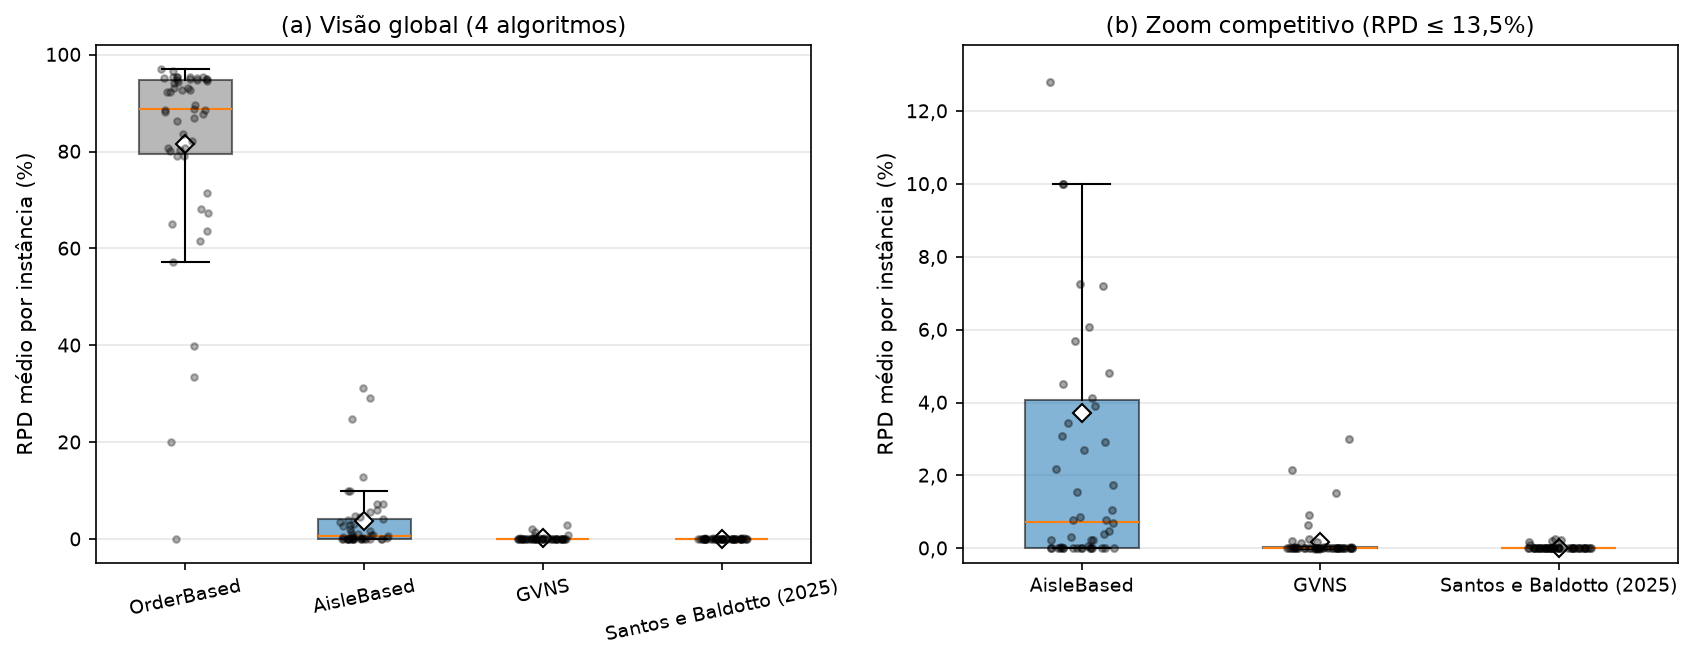

[LaTeX salvo] notebooks/resultados/tex/fig_boxplot_metaheuristicas.tex
[Figura salva] img/boxplot_metaheuristicas.pdf | img/boxplot_metaheuristicas.png


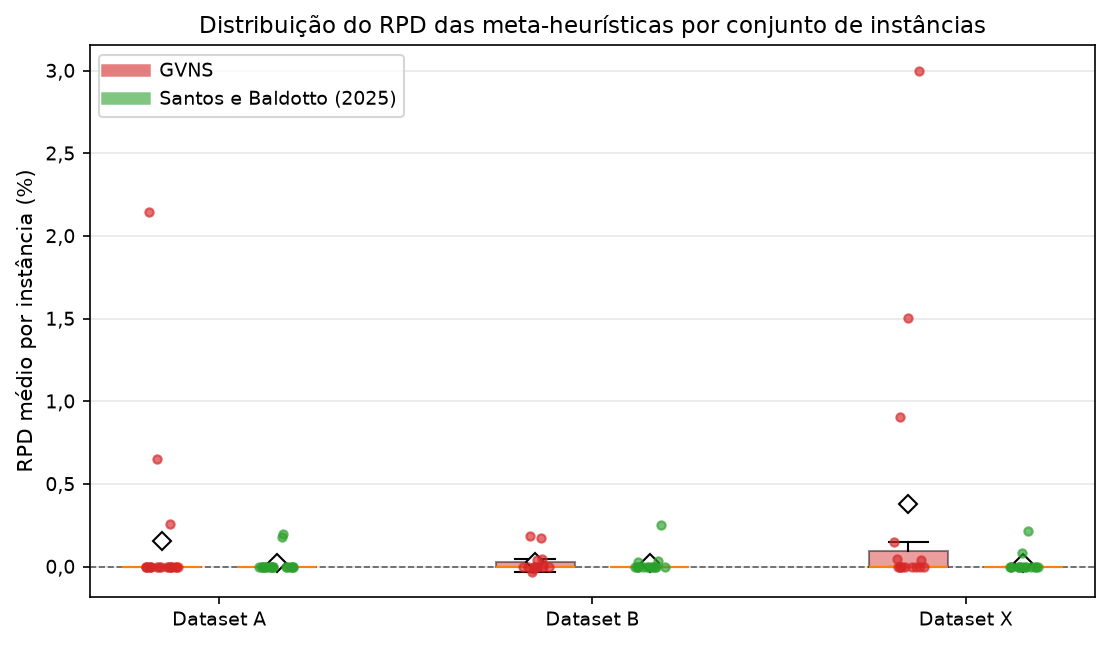

In [5]:
# --- Figura 3A: Boxplots com Zoom Competitivo ---
rng_j = np.random.default_rng(RNG_SEED)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), gridspec_kw={"width_ratios": [1.0, 1.0]})

# (a) Todos os 4 algoritmos
dados_all = [RPD[a].values for a in NOMES]
bp0 = axes[0].boxplot(
    dados_all, tick_labels=NOMES, patch_artist=True, showmeans=True, showfliers=False, widths=0.52,
    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
)
for patch, a in zip(bp0["boxes"], NOMES):
    patch.set_facecolor(COR[a]); patch.set_alpha(0.55)
for i, a in enumerate(NOMES):
    axes[0].scatter(i + 1 + rng_j.uniform(-0.14, 0.14, N), RPD[a].values, s=10, color="k", alpha=0.3, zorder=3)
axes[0].set_ylabel("RPD médio por instância (%)")
axes[0].set_title("(a) Visão global (4 algoritmos)")
axes[0].grid(alpha=0.3, axis="y")
axes[0].tick_params(axis="x", rotation=12)

# (b) Zoom nos 3 algoritmos competitivos
dados_comp = [RPD[a].values for a in COMPETITIVOS]
bp1 = axes[1].boxplot(
    dados_comp, tick_labels=COMPETITIVOS, patch_artist=True, showmeans=True, showfliers=False, widths=0.48,
    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
)
for patch, a in zip(bp1["boxes"], COMPETITIVOS):
    patch.set_facecolor(COR[a]); patch.set_alpha(0.55)
for i, a in enumerate(COMPETITIVOS):
    vals = RPD[a].values
    mask_in = vals <= 13.5
    axes[1].scatter(i + 1 + rng_j.uniform(-0.14, 0.14, mask_in.sum()), vals[mask_in], s=11, color="k", alpha=0.35, zorder=3)
axes[1].set_ylim(-0.4, 13.8)
axes[1].set_ylabel("RPD médio por instância (%)")
axes[1].set_title("(b) Zoom competitivo (RPD ≤ 13,5%)")
axes[1].grid(alpha=0.3, axis="y")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: vrg(f"{y:.1f}")))

fig.tight_layout()
salvar_fig(
    fig,
    "boxplot_rpd",
    r"Distribuição do RPD médio por instância (30 sementes): (a) visão global dos quatro algoritmos e (b) zoom competitivo sobre \texttt{AisleBased}, \texttt{ILS-VND} e \texttt{Santos e Baldotto (2025)}. Losangos brancos indicam a média amostral.",
    "fig:boxplot_rpd",
    width=r"0.9\textwidth",
)
plt.show()

# --- Figura 3B: Confronto entre Meta-heurísticas por Dataset ---
fig, ax = plt.subplots(figsize=(7.5, 4.4))

dados_meta_ds = []
cores_meta_ds = []
xticks_pos, xticks_lab = [], []
for idx_d, d in enumerate(["a", "b", "x"]):
    sel = ds_idx == d
    p1, p2 = idx_d * 2.6 + 1.0, idx_d * 2.6 + 1.8
    xticks_pos.append((p1 + p2) / 2.0)
    xticks_lab.append(f"Dataset {d.upper()}")
    for p, a in [(p1, "ILS-VND"), (p2, "Santos e Baldotto (2025)")]:
        vals = RPD.loc[sel, a].values
        dados_meta_ds.append(vals)
        cores_meta_ds.append(COR[a])
        ax.scatter(p + rng_j.uniform(-0.12, 0.12, len(vals)), vals, s=16, color=COR[a], alpha=0.65, zorder=3)

positions_all = [idx_d * 2.6 + offset for idx_d in range(3) for offset in (1.0, 1.8)]
bp2 = ax.boxplot(
    dados_meta_ds, positions=positions_all, widths=0.55, patch_artist=True, showmeans=True, showfliers=False,
    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
)
for patch, c in zip(bp2["boxes"], cores_meta_ds):
    patch.set_facecolor(c); patch.set_alpha(0.45)

ax.axhline(0, color="k", lw=0.8, ls="--", alpha=0.6)
ax.set_xticks(xticks_pos)
ax.set_xticklabels(xticks_lab)
ax.set_ylabel("RPD médio por instância (%)")
ax.set_title("Distribuição do RPD das meta-heurísticas por conjunto de instâncias")
ax.grid(alpha=0.3, axis="y")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: vrg(f"{y:.1f}")))
ax.plot([], [], color=COR["ILS-VND"], lw=6, alpha=0.6, label="ILS-VND")
ax.plot([], [], color=COR["Santos e Baldotto (2025)"], lw=6, alpha=0.6, label="Santos e Baldotto (2025)")
ax.legend(loc="upper left", frameon=True)

fig.tight_layout()
salvar_fig(
    fig,
    "boxplot_metaheuristicas",
    r"Comparação da distribuição do RPD entre as meta-heurísticas \texttt{ILS-VND} e \texttt{Santos e Baldotto (2025)} por conjunto de instâncias (Datasets A, B e X, médias de 30 sementes). Losangos brancos indicam a média amostral.",
    "fig:boxplot_metaheuristicas",
    width=r"0.7\textwidth",
)
plt.show()


## 6. Efeito do Refinamento Meta-heurístico `AisleBased` $\rightarrow$ `ILS-VND` (`refinamento_ils_vnd.pdf` e `refinamento_faixas.pdf`)

Demonstra visualmente o **Resultado R2** sob duas perspectivas complementares:
- **`refinamento_ils_vnd.pdf`**: Redução pontual do RPD nas 22 instâncias em que a solução inicial do `AisleBased` apresentava $\text{RPD} > 1\%$ (gráfico *dumbbell*).
- **`refinamento_faixas.pdf`**: Migração macro das 50 instâncias entre faixas de qualidade de RPD antes ($s_0$) e após ($s^*$) o refinamento meta-heurístico.


[LaTeX salvo] notebooks/resultados/tex/fig_refinamento_gvns.tex
[Figura salva] img/refinamento_gvns.pdf | img/refinamento_gvns.png


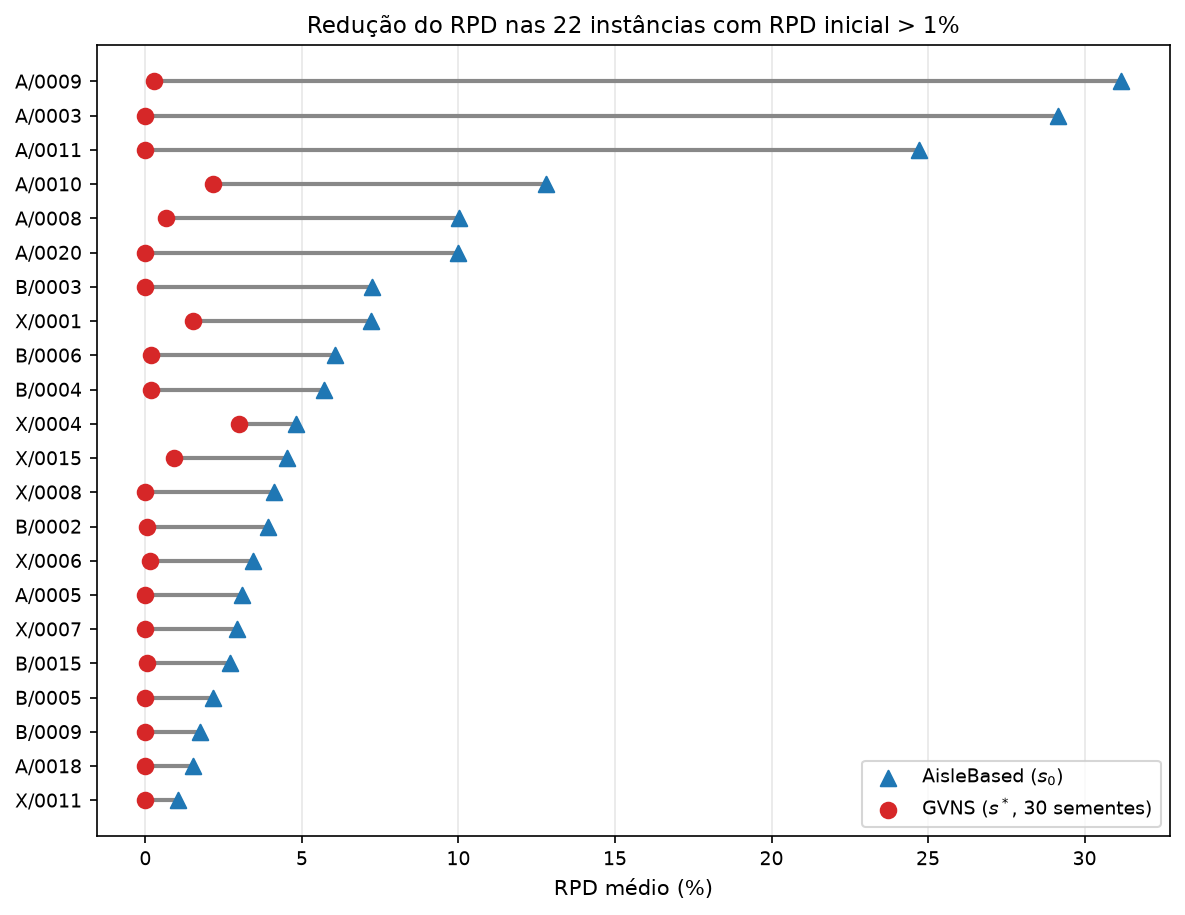

[LaTeX salvo] notebooks/resultados/tex/fig_refinamento_faixas.tex
[Figura salva] img/refinamento_faixas.pdf | img/refinamento_faixas.png


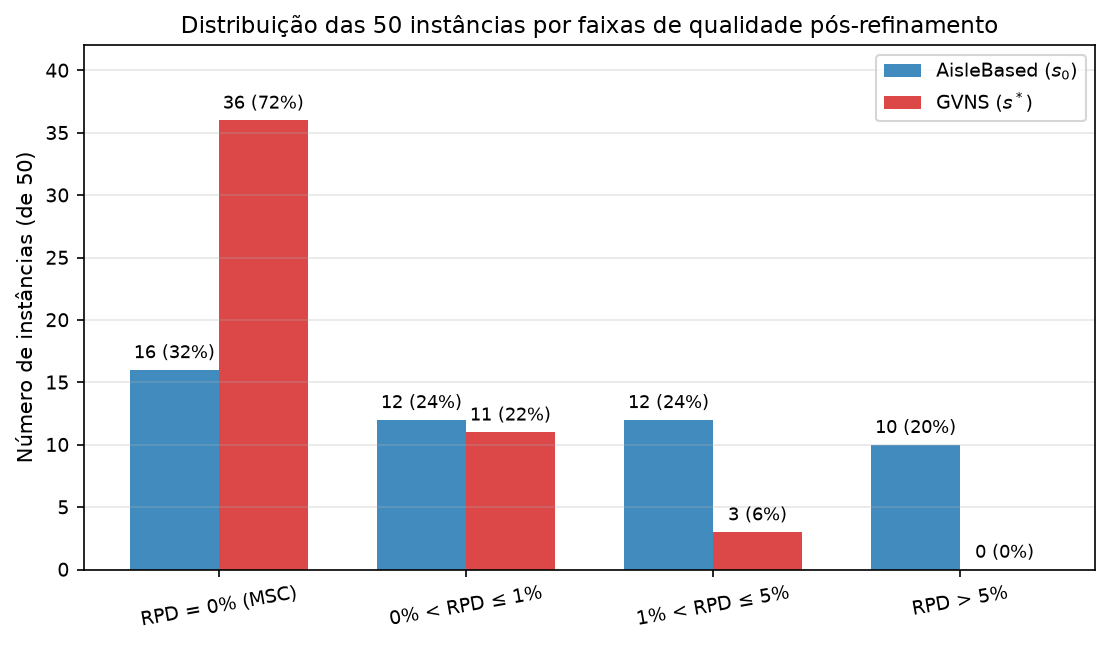

In [6]:
# --- Figura 4A: Refinamento AisleBased -> ILS-VND (Dumbbell por Instância) ---
df_ref = pd.DataFrame({
    "dataset": OBJ.index.get_level_values("dataset"),
    "instance": OBJ.index.get_level_values("instance"),
    "rpd_aisle": RPD["AisleBased"].values,
    "rpd_ils_vnd": RPD["ILS-VND"].values,
})
df_ref["rotulo"] = df_ref["dataset"].str.upper() + "/" + df_ref["instance"].str.replace("instance_", "").str.replace(".txt", "")
df_gt1 = df_ref[df_ref["rpd_aisle"] > 1.0].sort_values("rpd_aisle", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.0, 6.2))

y_pos = np.arange(len(df_gt1))
ax.hlines(y_pos, df_gt1["rpd_ils_vnd"], df_gt1["rpd_aisle"], color="#888888", lw=2.0, zorder=2)
ax.scatter(df_gt1["rpd_aisle"], y_pos, color=COR["AisleBased"], s=55, marker="^", label=r"AisleBased ($s_0$)", zorder=3)
ax.scatter(df_gt1["rpd_ils_vnd"], y_pos, color=COR["ILS-VND"], s=55, marker="o", label=r"ILS-VND ($s^*$, 30 sementes)", zorder=4)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_gt1["rotulo"], fontsize=9.0)
ax.set_xlabel("RPD médio (%)")
ax.set_title(f"Redução do RPD nas {len(df_gt1)} instâncias com RPD inicial > 1%")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: vrg(f"{x:.0f}")))
ax.grid(alpha=0.3, axis="x")
ax.legend(loc="lower right", frameon=True)

fig.tight_layout()
salvar_fig(
    fig,
    "refinamento_ils_vnd",
    r"Redução do RPD proporcionada pelo refinamento meta-heurístico do \texttt{ILS-VND} a partir da solução inicial do \texttt{AisleBased} nas 22 instâncias em que o gap inicial excedia $1\%$. Triângulos azuis representam a solução inicial $s_0$; círculos vermelhos indicam a média das soluções finais $s^*$ (30 sementes).",
    "fig:refinamento_ils_vnd",
    width=r"0.75\textwidth",
)
plt.show()

# --- Figura 4B: Migração de Faixas de Qualidade Pós-refinamento ---
fig, ax = plt.subplots(figsize=(7.5, 4.4))

def contar_faixas(s_rpd, s_obj):
    msc = s_obj >= BEST * (1.0 - TOL)
    f1 = msc.sum()
    f2 = ((~msc) & (s_rpd <= 1.0)).sum()
    f3 = ((s_rpd > 1.0) & (s_rpd <= 5.0)).sum()
    f4 = (s_rpd > 5.0).sum()
    return [int(f1), int(f2), int(f3), int(f4)]

faixas_nomes = ["RPD = 0% (MSC)", "0% < RPD ≤ 1%", "1% < RPD ≤ 5%", "RPD > 5%"]
c_aisle = contar_faixas(RPD["AisleBased"], OBJ["AisleBased"])
c_ils_vnd = contar_faixas(RPD["ILS-VND"], OBJ["ILS-VND"])

x_f = np.arange(len(faixas_nomes))
w_f = 0.36
b1 = ax.bar(x_f - w_f/2, c_aisle, width=w_f, color=COR["AisleBased"], alpha=0.85, label=r"AisleBased ($s_0$)")
b2 = ax.bar(x_f + w_f/2, c_ils_vnd, width=w_f, color=COR["ILS-VND"], alpha=0.85, label=r"ILS-VND ($s^*$)")

for bars in (b1, b2):
    for bar in bars:
        h = int(bar.get_height())
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.6, f"{h} ({h*2}%)", ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x_f)
ax.set_xticklabels(faixas_nomes, rotation=10)
ax.set_ylim(0, 42)
ax.set_ylabel("Número de instâncias (de 50)")
ax.set_title("Distribuição das 50 instâncias por faixas de qualidade pós-refinamento")
ax.grid(alpha=0.3, axis="y")
ax.legend(loc="upper right", frameon=True)

fig.tight_layout()
salvar_fig(
    fig,
    "refinamento_faixas",
    r"Distribuição das 50 instâncias avaliadas por faixas de qualidade de RPD antes ($s_0$, \texttt{AisleBased}) e após o refinamento meta-heurístico ($s^*$, \texttt{ILS-VND}). Observa-se a elevação de soluções ótimas/MSC de 16 ($32\%$) para 36 ($72\%$) e a completa eliminação de soluções com gap superior a $5\%$.",
    "fig:refinamento_faixas",
    width=r"0.7\textwidth",
)
plt.show()


## 7. Compromisso Tempo $\times$ Qualidade e Estabilidade entre Sementes (`tradeoff_tempo_qualidade.pdf` e `estabilidade_sementes.pdf`)

Demonstra o **Resultado R5** sob duas perspectivas complementares:
- **`tradeoff_tempo_qualidade.pdf`**: Compromisso entre Tempo Médio de Execução (escala logarítmica) e RPD Médio (%) por conjunto de instâncias e no Geral, com a Fronteira de Pareto.
- **`estabilidade_sementes.pdf`**: Desvio padrão do RPD entre as 30 sementes nas únicas 12 instâncias (de 50) que apresentaram variabilidade estocástica não nula.


[LaTeX salvo] notebooks/resultados/tex/fig_tradeoff_tempo_qualidade.tex
[Figura salva] img/tradeoff_tempo_qualidade.pdf | img/tradeoff_tempo_qualidade.png


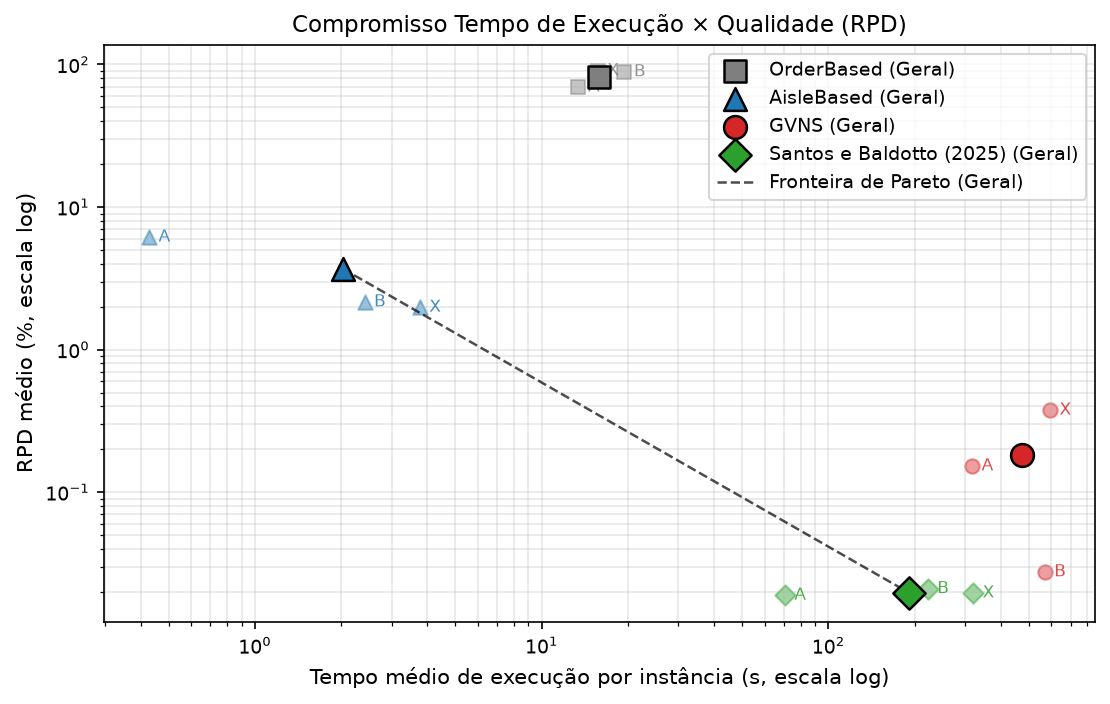

[LaTeX salvo] notebooks/resultados/tex/fig_estabilidade_sementes.tex
[Figura salva] img/estabilidade_sementes.pdf | img/estabilidade_sementes.png


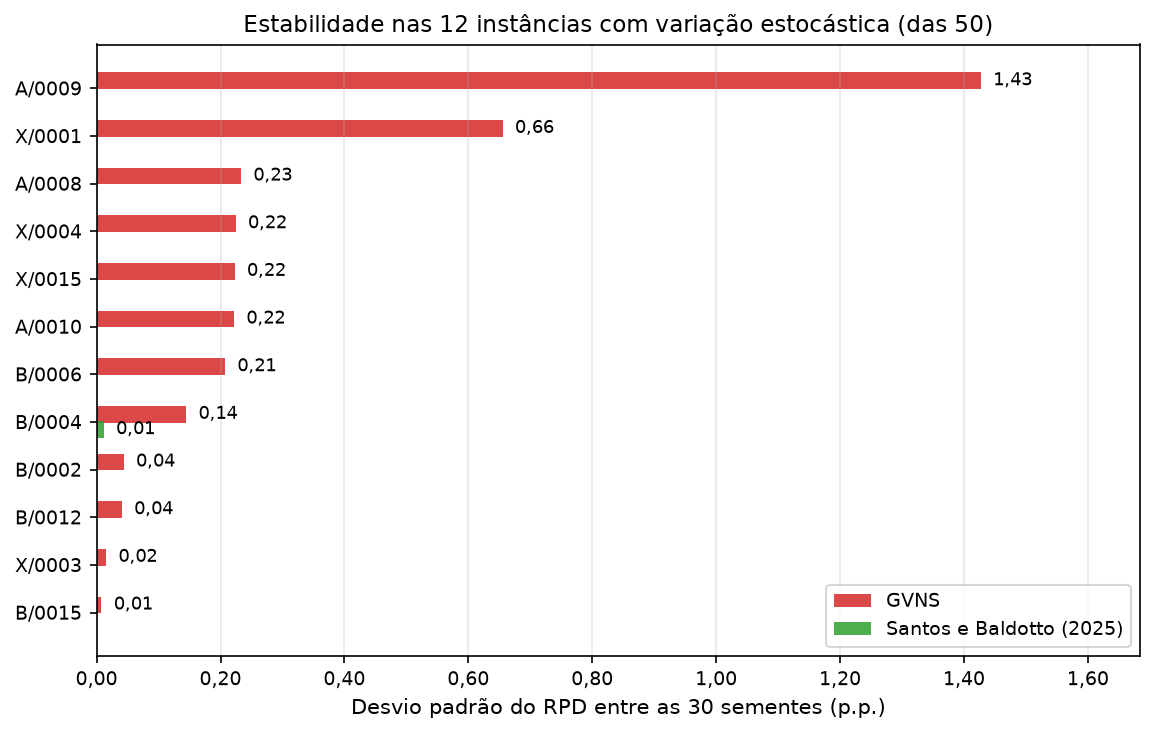

478

In [7]:
# --- Figura 5A: Compromisso Tempo × Qualidade ---
fig, ax = plt.subplots(figsize=(7.5, 4.8))

for a in NOMES:
    for d in ["a", "b", "x"]:
        sel = ds_idx == d
        tm = TEMPO.loc[sel, a].mean()
        rm = RPD.loc[sel, a].mean()
        ax.scatter(tm, rm, color=COR[a], marker=MARCADOR[a], s=48, alpha=0.45)
        ax.text(tm * 1.08, rm, d.upper(), fontsize=8.0, color=COR[a], alpha=0.85, va="center")

    tm_g = TEMPO[a].mean()
    rm_g = RPD[a].mean()
    ax.scatter(tm_g, rm_g, color=COR[a], marker=MARCADOR[a], s=120, edgecolor="k", lw=1.2, label=f"{a} (Geral)", zorder=5)

pareto_t = [TEMPO["AisleBased"].mean(), TEMPO["Santos e Baldotto (2025)"].mean()]
pareto_r = [RPD["AisleBased"].mean(), RPD["Santos e Baldotto (2025)"].mean()]
ax.plot(pareto_t, pareto_r, color="k", ls="--", lw=1.2, alpha=0.7, label="Fronteira de Pareto (Geral)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Tempo médio de execução por instância (s, escala log)")
ax.set_ylabel("RPD médio (%, escala log)")
ax.set_title("Compromisso Tempo de Execução × Qualidade (RPD)")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="upper right", frameon=True)

fig.tight_layout()
salvar_fig(
    fig,
    "tradeoff_tempo_qualidade",
    r"Compromisso entre tempo médio de execução e qualidade da solução (RPD médio) em escala bi-logarítmica por conjunto de instâncias (Datasets A, B e X) e consolidado (Geral, 30 sementes). A linha tracejada demarca a fronteira de Pareto amostral.",
    "fig:tradeoff_tempo_qualidade",
    width=r"0.75\textwidth",
)
plt.show()

# --- Figura 5B: Estabilidade Estocástica entre Sementes ---
fig, ax = plt.subplots(figsize=(7.8, 5.0))

dp_ils_vnd = RPD_DP["ILS-VND"]
dp_feijo = RPD_DP["Santos e Baldotto (2025)"]
dp_order = RPD_DP["OrderBased"]
mask_var = (dp_ils_vnd > 0.005) | (dp_feijo > 0.005) | (dp_order > 0.005)

df_var = pd.DataFrame({
    "rotulo": [f"{d.upper()}/{i.replace('instance_', '').replace('.txt', '')}" for d, i in RPD_DP.index[mask_var]],
    "ILS-VND": dp_ils_vnd[mask_var].values,
    "Santos e Baldotto (2025)": dp_feijo[mask_var].values,
    "OrderBased": dp_order[mask_var].values,
}).sort_values("ILS-VND", ascending=True).reset_index(drop=True)

y_v = np.arange(len(df_var))
ax.barh(y_v + 0.16, df_var["ILS-VND"], height=0.35, color=COR["ILS-VND"], alpha=0.85, label="ILS-VND")
ax.barh(y_v - 0.16, df_var["Santos e Baldotto (2025)"], height=0.35, color=COR["Santos e Baldotto (2025)"], alpha=0.85, label="Santos e Baldotto (2025)")
for idx_r, row in df_var.iterrows():
    if row["ILS-VND"] > 0.005:
        ax.text(row["ILS-VND"] + 0.02, idx_r + 0.16, fmt_num(row["ILS-VND"], 2), va="center", fontsize=8.5)
    if row["Santos e Baldotto (2025)"] > 0.005:
        ax.text(row["Santos e Baldotto (2025)"] + 0.02, idx_r - 0.16, fmt_num(row["Santos e Baldotto (2025)"], 2), va="center", fontsize=8.5)

ax.set_yticks(y_v)
ax.set_yticklabels(df_var["rotulo"], fontsize=9.0)
ax.set_xlim(0, max(df_var["ILS-VND"]) * 1.18)
ax.set_xlabel("Desvio padrão do RPD entre as 30 sementes (p.p.)")
ax.set_title(f"Estabilidade nas {len(df_var)} instâncias com variação estocástica (das 50)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: vrg(f"{x:.2f}")))
ax.grid(alpha=0.3, axis="x")
ax.legend(loc="lower right", frameon=True)

fig.tight_layout()
salvar_fig(
    fig,
    "estabilidade_sementes",
    r"Desvio padrão do RPD entre as 30 sementes nas únicas 12 instâncias (de 50) que apresentaram variabilidade não nula ($\text{DP} > 0{,}005\text{ p.p.}$). Nas demais 38 instâncias ambos os métodos convergiram rigorosamente para o mesmo objetivo em todas as replicações.",
    "fig:estabilidade_sementes",
    width=r"0.75\textwidth",
)
plt.show()

# Compatibilidade: espelhar arquivo legado para fig_tradeoff_estabilidade.tex
(TEX / "fig_tradeoff_estabilidade.tex").write_text((TEX / "fig_tradeoff_tempo_qualidade.tex").read_text())


## 8. Descoberta de Novas Melhores Soluções Conhecidas em `B/0012` e `B/0013` (`novas_msc_comparativo_b0012.pdf`, `novas_msc_comparativo_b0013.pdf` e `novas_msc_sementes.pdf`)

Demonstra visualmente o **Resultado R4**:
- **`novas_msc_comparativo_b0012.pdf`**: Comparação direta da evolução de unidades coletadas e razão objetivo ($f = \text{Unidades}/\text{Corredores}$) frente à MSC anterior na instância `B/0012` ($\lvert\mathcal{A}'\rvert = 11$, $\lvert\mathcal{O}'\rvert = 6\,244$).
- **`novas_msc_comparativo_b0013.pdf`**: Comparação direta da evolução de unidades coletadas e razão objetivo frente à MSC anterior na instância `B/0013` ($\lvert\mathcal{A}'\rvert = 9$, $\lvert\mathcal{O}'\rvert = 6\,813$).
- **`novas_msc_sementes.pdf`**: Distribuição detalhada dos patamares discretos alcançados pelas 30 sementes do `ILS-VND` em `B/0012` (13 de 30 sementes acima da MSC, até $+8$ unidades) e convergência unânime (30 de 30 sementes acima da MSC) em `B/0013`.


[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_comparativo_b0012.tex
[Figura salva] img/novas_msc_comparativo_b0012.pdf | img/novas_msc_comparativo_b0012.png


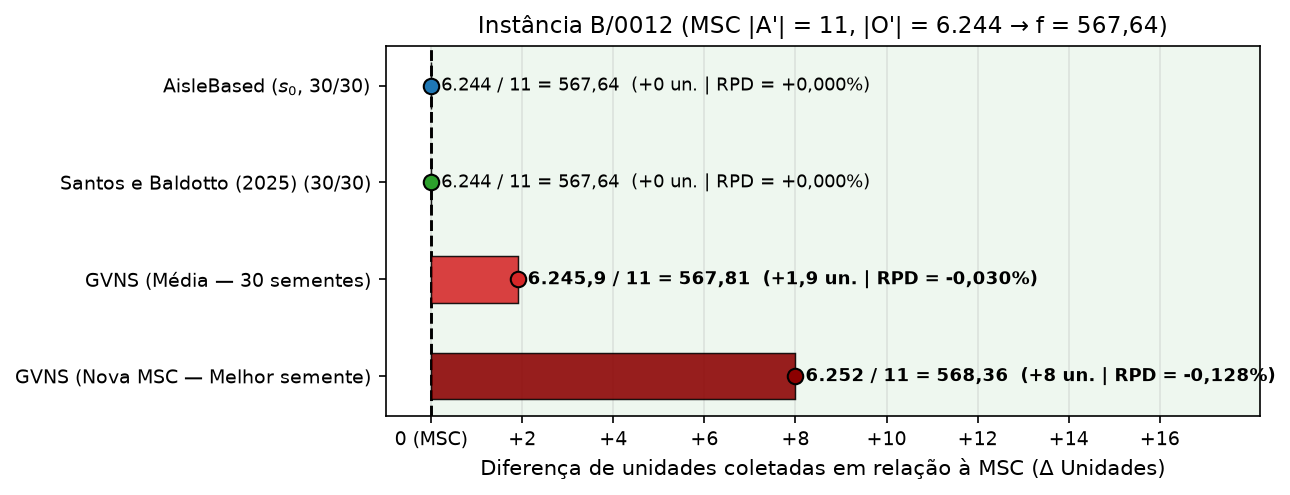

[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_comparativo_b0013.tex
[Figura salva] img/novas_msc_comparativo_b0013.pdf | img/novas_msc_comparativo_b0013.png


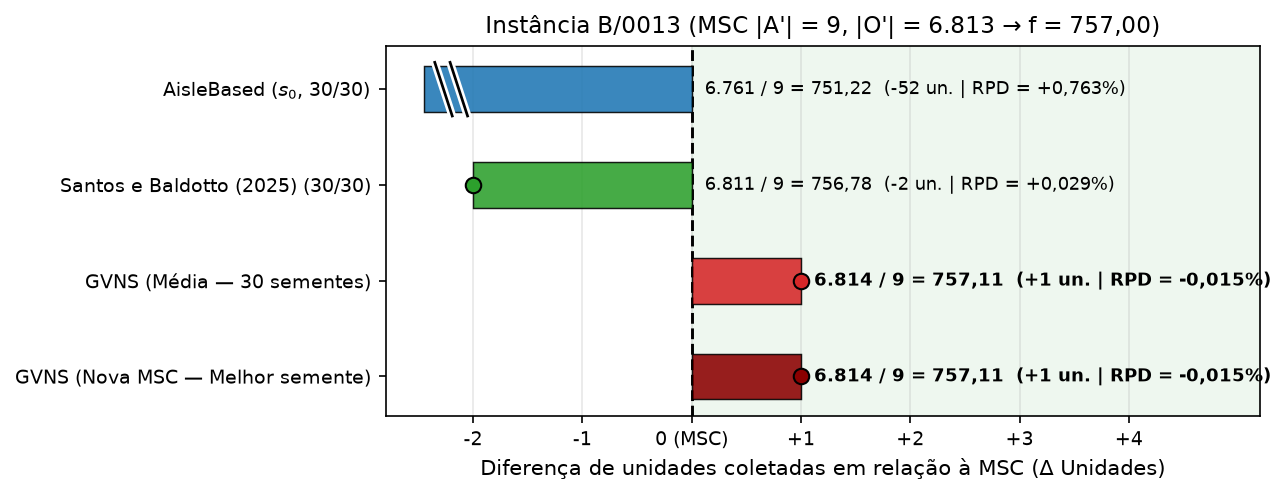

[LaTeX salvo] notebooks/resultados/tex/fig_novas_msc_sementes.tex
[Figura salva] img/novas_msc_sementes.pdf | img/novas_msc_sementes.png


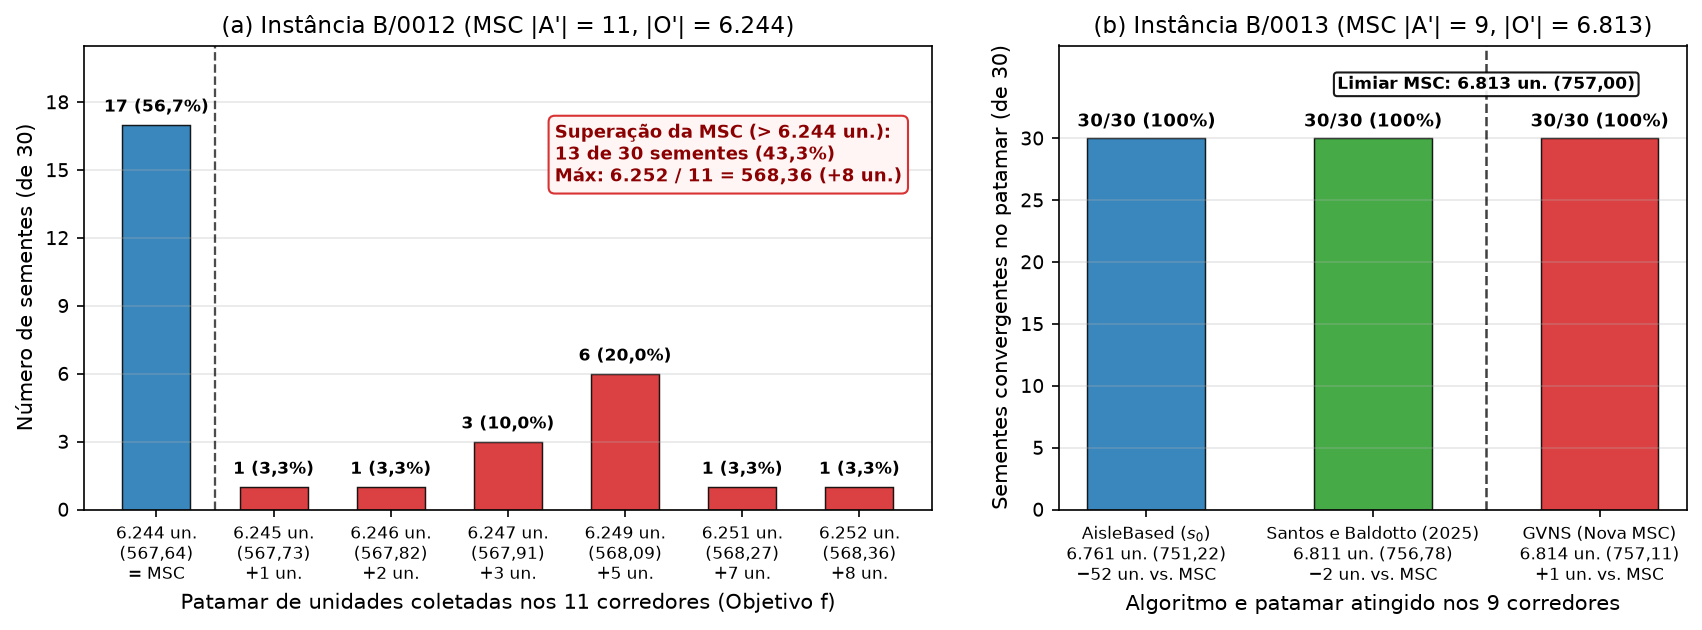

In [8]:
# --- Figura 6A-1: Comparativo Direto frente à MSC em B/0012 ---
sub_b12 = raw[(raw["dataset"] == "b") & (raw["instance"] == "instance_0012.txt")]
sub_b13 = raw[(raw["dataset"] == "b") & (raw["instance"] == "instance_0013.txt")]

fig, ax = plt.subplots(figsize=(8.6, 3.4))

bks_u12 = 6244.0
bks_f12 = bks_u12 / 11.0
ils_vnd_u12_mean = sub_b12[sub_b12["algo"] == "ILS-VND"]["items"].mean()
ils_vnd_u12_max = sub_b12[sub_b12["algo"] == "ILS-VND"]["items"].max()

metodos_12 = [
    ("AisleBased ($s_0$, 30/30)", 6244.0, COR["AisleBased"]),
    ("Santos e Baldotto (2025) (30/30)", 6244.0, COR["Santos e Baldotto (2025)"]),
    ("ILS-VND (Média — 30 sementes)", ils_vnd_u12_mean, COR["ILS-VND"]),
    ("ILS-VND (Nova MSC — Melhor semente)", float(ils_vnd_u12_max), "#8b0000"),
]

y12 = np.arange(len(metodos_12))
deltas_12 = [m[1] - bks_u12 for m in metodos_12]
cores_12 = [m[2] for m in metodos_12]

ax.axvspan(0.0, 18.2, color="#e8f5e9", alpha=0.7, zorder=0, label="Zona de superação da MSC (RPD < 0%)")
ax.axvline(0.0, color="k", lw=1.4, ls="--", zorder=2, label="MSC: 6.244 / 11 = 567,64")

bars12 = ax.barh(y12, deltas_12, height=0.48, color=cores_12, alpha=0.88, edgecolor="k", lw=0.7, zorder=3)
for idx_m, (rot, u_val, c_m) in enumerate(metodos_12):
    d_u = u_val - bks_u12
    f_val = u_val / 11.0
    rpd_val = (bks_f12 - f_val) / bks_f12 * 100.0
    ax.scatter(d_u, idx_m, color=c_m, edgecolor="k", s=55, zorder=4)
    if abs(u_val - round(u_val)) > 1e-4:
        int_p = int(u_val)
        dec_p = int(round((u_val - int_p) * 10))
        u_str = f"{int_p:,}".replace(",", ".") + f",{dec_p}"
    else:
        u_str = f"{int(round(u_val)):,}".replace(",", ".")
    d_str = fmt_num(d_u, 1, sinal=True) if abs(d_u - round(d_u)) > 1e-4 else f"{int(round(d_u)):+d}"
    txt = f"{u_str} / 11 = {fmt_num(f_val, 2)}  ({d_str} un. | RPD = {fmt_num(rpd_val, 3, sinal=True)}%)"
    ax.text(max(d_u, 0.0) + 0.22, idx_m, txt, va="center", fontsize=8.5, fontweight="bold" if d_u > 0 else "normal")

ax.set_yticks(y12)
ax.set_yticklabels([m[0] for m in metodos_12], fontsize=9.0)
ax.invert_yaxis()
ax.set_xlim(-1.0, 18.2)
ax.set_xticks([0, 2, 4, 6, 8, 10, 12, 14, 16])
ax.set_xlabel("Diferença de unidades coletadas em relação à MSC (Δ Unidades)")
ax.set_title("Instância B/0012 (MSC |A'| = 11, |O'| = 6.244 → f = 567,64)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):+d}" if x != 0 else "0 (MSC)"))
ax.grid(alpha=0.3, axis="x")

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_comparativo_b0012",
    r"Confronto frente à Melhor Solução Conhecida (MSC: $\lvert\mathcal{A}'\rvert = 11$, $\lvert\mathcal{O}'\rvert = 6\,244$, $f = 567{,}64$) na instância \texttt{B/0012}. Tanto \texttt{AisleBased} quanto \texttt{Santos e Baldotto (2025)} estacionam na MSC anterior, enquanto o refinamento em nível de pedidos do \texttt{ILS-VND} empacota em média $+1{,}9$ unidades extras ($f = 567{,}81$) e atinge até $+8$ unidades extras na melhor semente ($6\,252/11 = 568{,}36$, $\mathrm{RPD} = -0{,}128\%$).",
    "fig:novas_msc_comparativo_b0012",
    width=r"0.85\textwidth",
)
plt.show()

# --- Figura 6A-2: Comparativo Direto frente à MSC em B/0013 ---
fig, ax2 = plt.subplots(figsize=(8.6, 3.4))

bks_u13 = 6813.0
bks_f13 = bks_u13 / 9.0
ils_vnd_u13_mean = sub_b13[sub_b13["algo"] == "ILS-VND"]["items"].mean()
ils_vnd_u13_max = sub_b13[sub_b13["algo"] == "ILS-VND"]["items"].max()

metodos_13 = [
    ("AisleBased ($s_0$, 30/30)", 6761.0, COR["AisleBased"]),
    ("Santos e Baldotto (2025) (30/30)", 6811.0, COR["Santos e Baldotto (2025)"]),
    ("ILS-VND (Média — 30 sementes)", ils_vnd_u13_mean, COR["ILS-VND"]),
    ("ILS-VND (Nova MSC — Melhor semente)", float(ils_vnd_u13_max), "#8b0000"),
]

y13 = np.arange(len(metodos_13))
deltas_13 = [m[1] - bks_u13 for m in metodos_13]
cores_13 = [m[2] for m in metodos_13]

ax2.axvspan(0.0, 5.2, color="#e8f5e9", alpha=0.7, zorder=0, label="Zona de superação da MSC (RPD < 0%)")
ax2.axvline(0.0, color="k", lw=1.4, ls="--", zorder=2, label="MSC: 6.813 / 9 = 757,00")

for idx_m, (rot, u_val, c_m) in enumerate(metodos_13):
    d_u = u_val - bks_u13
    f_val = u_val / 9.0
    rpd_val = (bks_f13 - f_val) / bks_f13 * 100.0
    if d_u < -10.0:  # AisleBased (-52 un.) com corte e escala truncada
        ax2.barh(idx_m, -2.45, height=0.48, color=c_m, alpha=0.88, edgecolor="k", lw=0.7, zorder=3)
        dx, dy = 0.08, 0.28
        for offset in [-0.07, +0.07]:
            ax2.plot([-2.2 + offset - dx, -2.2 + offset + dx], [idx_m - dy, idx_m + dy], color="white", lw=3.8, zorder=5, clip_on=False)
            ax2.plot([-2.2 + offset - dx, -2.2 + offset + dx], [idx_m - dy, idx_m + dy], color="k", lw=1.3, zorder=6, clip_on=False)
        txt = f"6.761 / 9 = 751,22  (-52 un. | RPD = +0,763%)"
        ax2.text(0.12, idx_m, txt, va="center", fontsize=8.5, color="k", fontweight="normal")
    else:
        ax2.barh(idx_m, d_u, height=0.48, color=c_m, alpha=0.88, edgecolor="k", lw=0.7, zorder=3)
        ax2.scatter(d_u, idx_m, color=c_m, edgecolor="k", s=55, zorder=4)
        u_str = f"{int(round(u_val)):,}".replace(",", ".")
        d_str = f"{int(round(d_u)):+d}"
        txt = f"{u_str} / 9 = {fmt_num(f_val, 2)}  ({d_str} un. | RPD = {fmt_num(rpd_val, 3, sinal=True)}%)"
        pos_x = max(d_u, 0.0) + 0.12
        ax2.text(pos_x, idx_m, txt, va="center", fontsize=8.5, fontweight="bold" if d_u > 0 else "normal")

ax2.set_yticks(y13)
ax2.set_yticklabels([m[0] for m in metodos_13], fontsize=9.0)
ax2.invert_yaxis()
ax2.set_xlim(-2.8, 5.2)
ax2.set_xticks([-2, -1, 0, 1, 2, 3, 4])
ax2.set_xlabel("Diferença de unidades coletadas em relação à MSC (Δ Unidades)")
ax2.set_title("Instância B/0013 (MSC |A'| = 9, |O'| = 6.813 → f = 757,00)")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):+d}" if x != 0 else "0 (MSC)"))
ax2.grid(alpha=0.3, axis="x")

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_comparativo_b0013",
    r"Confronto frente à Melhor Solução Conhecida (MSC: $\lvert\mathcal{A}'\rvert = 9$, $\lvert\mathcal{O}'\rvert = 6\,813$, $f = 757{,}00$) na instância \texttt{B/0013}. A solução inicial do \texttt{AisleBased} parte de $-52$ unidades abaixo da MSC (barra truncada); \texttt{Santos e Baldotto (2025)} estaciona em $-2$ unidades ($6\,811/9 = 756{,}78$); e o \texttt{ILS-VND} converge em 100\% das sementes (30/30) para $+1$ unidade acima da MSC ($6\,814/9 = 757{,}11$, $\mathrm{RPD} = -0{,}015\%$).",
    "fig:novas_msc_comparativo_b0013",
    width=r"0.85\textwidth",
)
plt.show()

# --- Figura 6B: Distribuição das 30 Sementes do ILS-VND nas Instâncias com Nova MSC ---
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1.35, 1.0]})

# (a) Frequência dos 7 patamares discretos do ILS-VND em B/0012
cont_12 = sub_b12[sub_b12["algo"] == "ILS-VND"].groupby("items").size().sort_index()
u_vals_12 = cont_12.index.values
freq_12 = cont_12.values
x_pos_12 = np.arange(len(u_vals_12))
cores_bar_12 = [COR["AisleBased"] if u == 6244 else COR["ILS-VND"] for u in u_vals_12]

b_12 = axes[0].bar(x_pos_12, freq_12, width=0.58, color=cores_bar_12, alpha=0.88, edgecolor="k", lw=0.7)
for bar, u_v, cnt in zip(b_12, u_vals_12, freq_12):
    pct = cnt / 30.0 * 100.0
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        cnt + 0.4,
        f"{cnt} ({fmt_num(pct, 1)}%)",
        ha="center", va="bottom", fontsize=8.2, fontweight="bold"
    )

rotulos_x12 = [
    f"{u:,}".replace(",", ".") + f" un.\n({fmt_num(u/11.0, 2)})\n" + ("= MSC" if u == 6244 else f"+{u-6244} un.")
    for u in u_vals_12
]
axes[0].set_xticks(x_pos_12)
axes[0].set_xticklabels(rotulos_x12, fontsize=8.0)
axes[0].set_yticks([0, 3, 6, 9, 12, 15, 18])
axes[0].set_ylim(0, 20.5)
axes[0].set_ylabel("Número de sementes (de 30)")
axes[0].set_xlabel("Patamar de unidades coletadas nos 11 corredores (Objetivo f)")
axes[0].set_title("(a) Instância B/0012 (MSC |A'| = 11, |O'| = 6.244)")
axes[0].grid(alpha=0.3, axis="y")
axes[0].axvline(0.5, color="k", lw=1.1, ls="--", alpha=0.7)
axes[0].text(
    3.4, 14.5,
    "Superação da MSC (> 6.244 un.):\n13 de 30 sementes (43,3%)\nMáx: 6.252 / 11 = 568,36 (+8 un.)",
    fontsize=8.5, fontweight="bold", color="#8b0000",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#fff5f5", edgecolor=COR["ILS-VND"], alpha=0.95)
)

# (b) Comparação das 30 sementes por método em B/0013
niveis_13 = [
    ("AisleBased ($s_0$)\n6.761 un. (751,22)\n−52 un. vs. MSC", 30, COR["AisleBased"]),
    ("Santos e Baldotto (2025)\n6.811 un. (756,78)\n−2 un. vs. MSC", 30, COR["Santos e Baldotto (2025)"]),
    ("ILS-VND (Nova MSC)\n6.814 un. (757,11)\n+1 un. vs. MSC", 30, COR["ILS-VND"]),
]
x_pos_13 = np.arange(len(niveis_13))
b_13 = axes[1].bar(
    x_pos_13,
    [n[1] for n in niveis_13],
    width=0.52,
    color=[n[2] for n in niveis_13],
    alpha=0.88,
    edgecolor="k",
    lw=0.7
)
for bar in b_13:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        30.6,
        "30/30 (100%)",
        ha="center", va="bottom", fontsize=8.8, fontweight="bold"
    )

axes[1].axvline(1.5, color="k", lw=1.2, ls="--", alpha=0.75)
axes[1].text(1.5, 34.0, "Limiar MSC: 6.813 un. (757,00)", fontsize=8.0, fontweight="bold", ha="center",
             bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="k", alpha=0.9))
axes[1].set_xticks(x_pos_13)
axes[1].set_xticklabels([n[0] for n in niveis_13], fontsize=8.2)
axes[1].set_yticks([0, 5, 10, 15, 20, 25, 30])
axes[1].set_ylim(0, 37.5)
axes[1].set_ylabel("Sementes convergentes no patamar (de 30)")
axes[1].set_xlabel("Algoritmo e patamar atingido nos 9 corredores")
axes[1].set_title("(b) Instância B/0013 (MSC |A'| = 9, |O'| = 6.813)")
axes[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
salvar_fig(
    fig,
    "novas_msc_sementes",
    r"Distribuição das 30 sementes nas instâncias em que o \texttt{ILS-VND} estabeleceu novas Melhores Soluções Conhecidas: (a) em \texttt{B/0012} (MSC: $\lvert\mathcal{A}'\rvert = 11$, $\lvert\mathcal{O}'\rvert = 6\,244$), o \texttt{ILS-VND} supera a MSC em 13 das 30 sementes ($43{,}3\%$), distribuídas em 6 patamares superiores até $6\,252/11 = 568{,}36$; (b) em \texttt{B/0013} (MSC: $\lvert\mathcal{A}'\rvert = 9$, $\lvert\mathcal{O}'\rvert = 6\,813$), o \texttt{ILS-VND} converge de forma determinística (30/30 sementes) para $6\,814/9 = 757{,}11$, superando a MSC ($757{,}00$) e \texttt{Santos e Baldotto (2025)} ($6\,811/9 = 756{,}78$).",
    "fig:novas_msc_sementes",
    width=r"0.95\textwidth",
)
plt.show()


## 9. Tabelas Detalhadas por Instância para o Apêndice

**Revisões aplicadas**:
1. **`tabela_rpd_dp_{a,b,x}.tex`**: Corrigido o desvio padrão após $\pm$ para usar **`RPD_DP` (desvio padrão do RPD em p.p.)** em vez do desvio padrão da função objetivo bruta, adicionada coluna **MSC ($f^*$)** e linha final de **Média**.
2. **`tabela_obj_{a,b,x}.tex`**: Adicionada coluna **MSC ($f^*$)** e linha final de **Média**, mantendo o desvio padrão do objetivo (`OBJ_DP`).
3. **`tabela_apendice_{a,b,x}.tex`**: Versão unificada recomendada para o Apêndice (contendo **MSC ($f^*$)**, **Objetivo Médio** e **RPD Médio $\pm$ DP (%)** para cada algoritmo em uma única tabela por dataset).


In [9]:
for ds in DATASETS:
    sel = ds_idx == ds
    insts = [i.replace("instance_", "").replace(".txt", "") for i in OBJ.loc[sel].index.get_level_values("instance")]
    b_ds = BEST.loc[sel].values

    # 1) tabela_rpd_dp_{ds}.tex (CORRIGIDA: usa RPD_DP, inclui MSC e linha Média)
    L_rpd = [
        r"\begin{table}[htbp]",
        r"  \centering",
        rf"  \caption{{\label{{tab:rpd_dp_{ds}}} RPD médio (\%) $\pm$ desvio padrão do RPD (p.p.) por instância e algoritmo no Dataset~{ds.upper()} (30 sementes).}}",
        r"  \resizebox{\textwidth}{!}{",
        r"    \begin{tabular}{l r r r r r}",
        r"      \toprule",
        r"      \textbf{Instância} & \textbf{MSC ($f^*$)} & \textbf{OrderBased} & \textbf{AisleBased} & \textbf{ILS-VND} & \textbf{Santos e Baldotto (2025)} \\",
        r"      \midrule",
    ]
    for idx_i, cod in enumerate(insts):
        b_val = b_ds[idx_i]
        cels = []
        for a in NOMES:
            rm = RPD.loc[sel, a].iloc[idx_i]
            rsd = RPD_DP.loc[sel, a].iloc[idx_i]
            om = OBJ.loc[sel, a].iloc[idx_i]
            txt_c = fmt_pm(rm, rsd)
            if om >= b_val * (1.0 - TOL):
                txt_c = rf"\textbf{{{txt_c}}}"
            cels.append(txt_c)
        L_rpd.append(f"      {ds.upper()}/{cod} & {fmt_num(b_val)} & " + " & ".join(cels) + r" \\")
    L_rpd.append(r"      \midrule")
    medias_rpd = [fmt_pm(RPD.loc[sel, a].mean(), RPD.loc[sel, a].std(ddof=1), ocultar_dp_zero=False) for a in NOMES]
    L_rpd.append(f"      \\textbf{{Média}} & {fmt_num(b_ds.mean())} & " + " & ".join(medias_rpd) + r" \\")
    L_rpd += [
        r"      \bottomrule",
        r"    \end{tabular}",
        r"  }",
        r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026. Valores em negrito atingem ou superam a MSC.}",
        r"\end{table}",
    ]
    salvar_tex(f"tabela_rpd_dp_{ds}", L_rpd)

    # 2) tabela_obj_{ds}.tex (CORRIGIDA: inclui MSC e linha Média, usa OBJ_DP)
    L_obj = [
        r"\begin{table}[htbp]",
        r"  \centering",
        rf"  \caption{{\label{{tab:obj_{ds}}} Média da função objetivo $\pm$ desvio padrão por instância e algoritmo no Dataset~{ds.upper()} (30 sementes).}}",
        r"  \resizebox{\textwidth}{!}{",
        r"    \begin{tabular}{l r r r r r}",
        r"      \toprule",
        r"      \textbf{Instância} & \textbf{MSC ($f^*$)} & \textbf{OrderBased} & \textbf{AisleBased} & \textbf{ILS-VND} & \textbf{Santos e Baldotto (2025)} \\",
        r"      \midrule",
    ]
    for idx_i, cod in enumerate(insts):
        b_val = b_ds[idx_i]
        cels = []
        for a in NOMES:
            om = OBJ.loc[sel, a].iloc[idx_i]
            osd = OBJ_DP.loc[sel, a].iloc[idx_i]
            txt_c = fmt_pm(om, osd)
            if om >= b_val * (1.0 - TOL):
                txt_c = rf"\textbf{{{txt_c}}}"
            cels.append(txt_c)
        L_obj.append(f"      {ds.upper()}/{cod} & {fmt_num(b_val)} & " + " & ".join(cels) + r" \\")
    L_obj.append(r"      \midrule")
    medias_obj = [fmt_num(OBJ.loc[sel, a].mean()) for a in NOMES]
    L_obj.append(f"      \\textbf{{Média}} & {fmt_num(b_ds.mean())} & " + " & ".join(medias_obj) + r" \\")
    L_obj += [
        r"      \bottomrule",
        r"    \end{tabular}",
        r"  }",
        r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026. Valores em negrito atingem ou superam a MSC.}",
        r"\end{table}",
    ]
    salvar_tex(f"tabela_obj_{ds}", L_obj)

    # 3) tabela_apendice_{ds}.tex (UNIFICADA: MSC + Obj e RPD ± DP_rpd para cada algoritmo)
    L_ap = [
        r"\begin{table}[htbp]",
        r"  \centering",
        rf"  \caption{{\label{{tab:apendice_{ds}}} Resultados detalhados por instância no Dataset~{ds.upper()} (médias de 30 sementes: valor da função objetivo e $\mathrm{{RPD}} \pm \mathrm{{DP}}_{{\mathrm{{RPD}}}}$ em \%).}}",
        r"  \resizebox{\textwidth}{!}{",
        r"    \begin{tabular}{l r r r r r r r r r}",
        r"      \toprule",
        r"      \multirow{2}{*}{\textbf{Inst.}} & \multirow{2}{*}{\textbf{MSC ($f^*$)}} & "
        + " & ".join(rf"\multicolumn{{2}}{{c}}{{\textbf{{{a}}}}}" for a in NOMES) + r" \\",
        r"      \cmidrule(lr){3-4} \cmidrule(lr){5-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}",
        r"      & & " + " & ".join([r"\textbf{Obj.} & \textbf{RPD (\%)}"] * len(NOMES)) + r" \\",
        r"      \midrule",
    ]
    for idx_i, cod in enumerate(insts):
        b_val = b_ds[idx_i]
        cels = []
        for a in NOMES:
            om = OBJ.loc[sel, a].iloc[idx_i]
            rm = RPD.loc[sel, a].iloc[idx_i]
            rsd = RPD_DP.loc[sel, a].iloc[idx_i]
            s_o = fmt_num(om)
            s_r = fmt_pm(rm, rsd)
            if om >= b_val * (1.0 - TOL):
                s_o = rf"\textbf{{{s_o}}}"
                s_r = rf"\textbf{{{s_r}}}"
            cels.extend([s_o, s_r])
        L_ap.append(f"      {ds.upper()}/{cod} & {fmt_num(b_val)} & " + " & ".join(cels) + r" \\")
    L_ap.append(r"      \midrule")
    cels_m = []
    for a in NOMES:
        cels_m.append(fmt_num(OBJ.loc[sel, a].mean()))
        cels_m.append(fmt_pm(RPD.loc[sel, a].mean(), RPD.loc[sel, a].std(ddof=1), ocultar_dp_zero=False))
    L_ap.append(f"      \\textbf{{Média}} & {fmt_num(b_ds.mean())} & " + " & ".join(cels_m) + r" \\")
    L_ap += [
        r"      \bottomrule",
        r"    \end{tabular}",
        r"  }",
        r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026. Valores em negrito atingem ou superam a MSC.}",
        r"\end{table}",
    ]
    salvar_tex(f"tabela_apendice_{ds}", L_ap)


[LaTeX salvo] notebooks/resultados/tex/tabela_rpd_dp_a.tex


[LaTeX salvo] notebooks/resultados/tex/tabela_obj_a.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_apendice_a.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_rpd_dp_b.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_obj_b.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_apendice_b.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_rpd_dp_x.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_obj_x.tex
[LaTeX salvo] notebooks/resultados/tex/tabela_apendice_x.tex
